# Criteo DAC (Display Advertising) — Lightweight EDA (10K-row sample)

This notebook builds a **fast, cheap, repeatable** EDA workflow for CTR prediction using the **Criteo Display Advertising Challenge (dac-v1)** dataset.

**Important constraint:** for this first iteration we only load the **first 10,000 training rows**. All computed statistics are **sample statistics** (not full-dataset statistics).

We are not building a model yet. The goal is to understand the schema, missingness, feature distributions, and why high-cardinality categoricals matter for embeddings.

## 0. Setup
We keep the analysis lightweight and avoid full-file scans. We will: 
- read the dataset documentation (`readme.txt`)
- check file sizes using filesystem metadata
- load only `nrows=10_000` from `train.txt`
- compute *sample* statistics and a small number of plots

In [24]:
from __future__ import annotations

import math
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 140)

# Make paths robust to whether you launch Jupyter from the project root or from notebooks/.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'criteo_advertising_dataset').exists():
    PROJECT_ROOT = Path('..').resolve()

DATA_DIR = PROJECT_ROOT / 'criteo_advertising_dataset'
TRAIN_PATH = DATA_DIR / 'train.txt'
TEST_PATH = DATA_DIR / 'test.txt'
README_PATH = DATA_DIR / 'readme.txt'

SAMPLE_N = 1_000_000
SAMPLE_NOTE = f'All statistics below are computed on the first {SAMPLE_N:,} training rows (sample statistics). '


## 1. Dataset structure
Before touching the data, we confirm the schema from the official dataset documentation.

Why it matters for CTR modeling:
- We need to know **which columns are numeric vs. categorical**.
- We need to understand **how missing values are represented**.
- We should confirm whether rows have **temporal/chronological ordering** (important for proper evaluation and leakage avoidance).

In [25]:
readme_text = README_PATH.read_text(encoding='utf-8', errors='replace')
print(readme_text)

        ------ Display Advertising Challenge ------

Dataset: dac-v1

This dataset contains feature values and click feedback for millions of display 
ads. Its purpose is to benchmark algorithms for clickthrough rate (CTR) prediction.
It has been used for the Display Advertising Challenge hosted by Kaggle:
https://www.kaggle.com/c/criteo-display-ad-challenge/


Full description:

This dataset contains 2 files:
  train.txt
  test.txt
corresponding to the training and test parts of the data. 


Dataset construction:

The training dataset consists of a portion of Criteo's traffic over a period
of 7 days. Each row corresponds to a display ad served by Criteo and the first
column is indicates whether this ad has been clicked or not.
The positive (clicked) and negatives (non-clicked) examples have both been
subsampled (but at different rates) in order to reduce the dataset size.

There are 13 features taking integer values (mostly count features) and 26
categorical features. The values of th

In [26]:
def _format_bytes(n: int) -> str:
    # Human-friendly (binary) sizes
    units = ['B', 'KiB', 'MiB', 'GiB', 'TiB']
    x = float(n)
    for u in units:
        if x < 1024 or u == units[-1]:
            return f'{x:,.2f} {u}'
        x /= 1024
    return f'{n} B'

sizes = {
    'train.txt': TRAIN_PATH.stat().st_size,
    'test.txt': TEST_PATH.stat().st_size,
    'readme.txt': README_PATH.stat().st_size,
}
pd.DataFrame({
    'file': list(sizes.keys()),
    'bytes': list(sizes.values()),
    'pretty': [_format_bytes(v) for v in sizes.values()],
}).sort_values('bytes', ascending=False).reset_index(drop=True)

,file,bytes,pretty
0,train.txt,11147184845,10.38 GiB
1,test.txt,1460246311,1.36 GiB
2,readme.txt,1927,1.88 KiB


In [27]:
# Based on the dataset documentation (readme.txt):
NUM_INT_FEATURES = 13
NUM_CAT_FEATURES = 26

def make_column_names(has_label: bool) -> list[str]:
    numeric = [f'I{i}' for i in range(1, NUM_INT_FEATURES + 1)]
    cat = [f'C{i}' for i in range(1, NUM_CAT_FEATURES + 1)]
    if has_label:
        return ['label'] + numeric + cat
    return numeric + cat

train_columns = make_column_names(has_label=True)
test_columns = make_column_names(has_label=False)

pd.DataFrame({
    'split': ['train', 'test'],
    'has_label': [True, False],
    'num_numeric_features': [NUM_INT_FEATURES, NUM_INT_FEATURES],
    'num_categorical_features': [NUM_CAT_FEATURES, NUM_CAT_FEATURES],
    'total_columns': [len(train_columns), len(test_columns)],
})

,split,has_label,num_numeric_features,num_categorical_features,total_columns
0,train,True,13,26,40
1,test,False,13,26,39


### Load a small training sample (10K rows)
We load only the first 10,000 rows to validate the EDA workflow.

Note: empty fields in the tab-separated files represent missing values, and pandas will interpret them as `NaN`.

In [28]:
train_sample = pd.read_csv(
    TRAIN_PATH,
    sep='	',
    header=None,
    names=train_columns,
    nrows=SAMPLE_N,
    low_memory=False,
)

# Make sure label is numeric (it should be 0/1).
train_sample['label'] = pd.to_numeric(train_sample['label'], errors='coerce').astype('Int64')

# Coerce numeric features to numeric. Missing values remain NaN.
numeric_cols = [c for c in train_sample.columns if c.startswith('I')]
cat_cols = [c for c in train_sample.columns if c.startswith('C')]
for c in numeric_cols:
    train_sample[c] = pd.to_numeric(train_sample[c], errors='coerce')

print(SAMPLE_NOTE)
train_sample.head()

All statistics below are computed on the first 1,000,000 training rows (sample statistics). 


,label,I1,I2,I3,I4,I5,I6,I7,I8,I9,I10,I11,I12,I13,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,C15,C16,C17,C18,C19,C20,C21,C22,C23,C24,C25,C26
0,0,1.0,1,5.0,0.0,1382.0,4.0,15.0,2.0,181.0,1.0,2.0,NaN,2.0,68fd1e64,80e26c9b,fb936136,7b4723c4,25c83c98,7e0ccccf,de7995b8,1f89b562,a73ee510,a8cd5504,b2cb9c98,37c9c164,2824a5f6,1adce6ef,8ba8b39a,891b62e7,e5ba7672,f54016b9,21ddcdc9,b1252a9d,07b5194c,NaN,3a171ecb,c5c50484,e8b83407,9727dd16
1,0,2.0,0,44.0,1.0,102.0,8.0,2.0,2.0,4.0,1.0,1.0,NaN,4.0,68fd1e64,f0cf0024,6f67f7e5,41274cd7,25c83c98,fe6b92e5,922afcc0,0b153874,a73ee510,2b53e5fb,4f1b46f3,623049e6,d7020589,b28479f6,e6c5b5cd,c92f3b61,07c540c4,b04e4670,21ddcdc9,5840adea,60f6221e,NaN,3a171ecb,43f13e8b,e8b83407,731c3655
2,0,2.0,0,1.0,14.0,767.0,89.0,4.0,2.0,245.0,1.0,3.0,3.0,45.0,287e684f,0a519c5c,02cf9876,c18be181,25c83c98,7e0ccccf,c78204a1,0b153874,a73ee510,3b08e48b,5f5e6091,8fe001f4,aa655a2f,07d13a8f,6dc710ed,36103458,8efede7f,3412118d,NaN,NaN,e587c466,ad3062eb,3a171ecb,3b183c5c,NaN,NaN
3,0,NaN,893,NaN,NaN,4392.0,NaN,0.0,0.0,0.0,NaN,0.0,NaN,NaN,68fd1e64,2c16a946,a9a87e68,2e17d6f6,25c83c98,fe6b92e5,2e8a689b,0b153874,a73ee510,efea433b,e51ddf94,a30567ca,3516f6e6,07d13a8f,18231224,52b8680f,1e88c74f,74ef3502,NaN,NaN,6b3a5ca6,NaN,3a171ecb,9117a34a,NaN,NaN
4,0,3.0,-1,NaN,0.0,2.0,0.0,3.0,0.0,0.0,1.0,1.0,NaN,0.0,8cf07265,ae46a29d,c81688bb,f922efad,25c83c98,13718bbd,ad9fa255,0b153874,a73ee510,5282c137,e5d8af57,66a76a26,f06c53ac,1adce6ef,8ff4b403,01adbab4,1e88c74f,26b3c7a7,NaN,NaN,21c9516a,NaN,32c7478e,b34f3128,NaN,NaN


In [29]:
# Verify the test file does not contain labels by showing a few rows (no full scan).
test_head = pd.read_csv(
    TEST_PATH,
    sep='	',
    header=None,
    names=test_columns,
    nrows=5,
    low_memory=False,
)
test_head.head()

,I1,I2,I3,I4,I5,I6,I7,I8,I9,I10,I11,I12,I13,C1,C2,C3,C4,C5,C6,C7,C8,C9,C10,C11,C12,C13,C14,C15,C16,C17,C18,C19,C20,C21,C22,C23,C24,C25,C26
0,NaN,29,50.0,5,7260,437,1,4,14,NaN,1,0.0,6,5a9ed9b0,a0e12995,a1e14474,08a40877,25c83c98,NaN,964d1fdd,5b392875,a73ee510,de89c3d2,59cd5ae7,8d98db20,8b216f7b,1adce6ef,78c64a1d,3ecdadf7,3486227d,1616f155,21ddcdc9,5840adea,2c277e62,NaN,423fab69,54c91918,9b3e8820,e75c9ae9
1,27.0,17,45.0,28,2,28,27,29,28,1.0,1,NaN,23,68fd1e64,960c983b,9fbfbfd5,38c11726,25c83c98,7e0ccccf,fe06fd10,062b5529,a73ee510,ca53fc84,67360210,895d8bbb,4f8e2224,f862f261,b4cc2435,4c0041e5,e5ba7672,b4abdd09,21ddcdc9,5840adea,36a7ab86,NaN,32c7478e,85e4d73f,010f6491,ee63dd9b
2,1.0,1,19.0,7,1,3,1,7,7,1.0,1,NaN,2,09ca0b81,8947f767,a87e61f7,c4ba2a67,25c83c98,7e0ccccf,ce6020cc,062b5529,a73ee510,b04d3cfe,70dcd184,899eb56b,aca22cf9,b28479f6,a473257f,88f592e4,d4bb7bd8,bd17c3da,1d04f4a4,a458ea53,82bdc0bb,NaN,32c7478e,5bdcd9c4,010f6491,cca57dcc
3,4.0,1,NaN,6,1051,134,4,35,72,1.0,1,NaN,6,05db9164,532da141,a7ded28e,456b4d8c,25c83c98,fbad5c96,5f29da0e,0b153874,a73ee510,4b344a42,0ad37b4b,8ea37200,f9d99d81,cfef1c29,abd8f51e,9a9902d0,07c540c4,bdc06043,NaN,NaN,6dfd157c,ad3062eb,423fab69,ef089725,NaN,NaN
4,7.0,1,25.0,10,139,74,48,13,44,1.0,8,2.0,12,05db9164,207b2d81,2b280564,ad5ffc6b,25c83c98,7e0ccccf,103c17bc,0b153874,a73ee510,8e54038a,e6e0c2dc,2a064dba,e9332a03,07d13a8f,0c67c4ca,7d9b60c8,27c07bd6,395856b0,21ddcdc9,a458ea53,9c3eb598,ad3062eb,3a171ecb,c0b8dfd6,001f3601,7a2fb9af


## 2. Target distribution (sample CTR)
CTR prediction is typically a **class-imbalanced** problem (many more non-clicks than clicks).

Why it matters:
- affects baseline performance and metrics (e.g., AUC vs. logloss)
- affects calibration and thresholding
- affects sampling strategies (later)

Below is the **sample CTR** from the first 10K training rows.

In [30]:
label_counts = train_sample['label'].value_counts(dropna=False).sort_index()
pos = int(label_counts.get(1, 0))
neg = int(label_counts.get(0, 0))
total = int(train_sample.shape[0])
sample_ctr = pos / total
pos_neg_ratio = pos / max(neg, 1)

pd.DataFrame({
    'metric': ['rows', 'positives', 'negatives', 'sample_ctr', 'pos_to_neg_ratio'],
    'value': [total, pos, neg, sample_ctr, pos_neg_ratio],
})

,metric,value
0,rows,1000000.000000
1,positives,254949.000000
2,negatives,745051.000000
3,sample_ctr,0.254949
4,pos_to_neg_ratio,0.342190


## 3. Missingness (sample)
Missing values are common in CTR datasets. Handling missingness correctly matters for both:
- numeric preprocessing (e.g., imputation / learned missing embeddings)
- categorical vocabularies (e.g., dedicated missing token)

We compute missingness per feature on the 10K-row sample.

In [31]:
missing_counts = train_sample.isna().sum().rename('missing_count')
missing_pct = (missing_counts / len(train_sample)).rename('missing_pct')
missing_df = pd.concat([missing_counts, missing_pct], axis=1)

missing_numeric = missing_df.loc[numeric_cols].sort_values('missing_pct', ascending=False)
missing_cat = missing_df.loc[cat_cols].sort_values('missing_pct', ascending=False)

display(pd.DataFrame({'note': [SAMPLE_NOTE]}))
display(missing_numeric.head(13))
display(missing_cat.head(10))

,note
0,All statistics below are computed on the first...


,missing_count,missing_pct
I12,770057,0.770057
I1,423003,0.423003
I10,423003,0.423003
I4,249116,0.249116
I13,249116,0.249116
I3,235054,0.235054
I6,221740,0.221740
I7,40834,0.040834
I9,40834,0.040834
I11,40834,0.040834


,missing_count,missing_pct
C22,738959,0.738959
C26,483901,0.483901
C25,483901,0.483901
C20,483901,0.483901
C19,483901,0.483901
C6,119344,0.119344
C16,36345,0.036345
C3,36345,0.036345
C4,36345,0.036345
C24,36345,0.036345


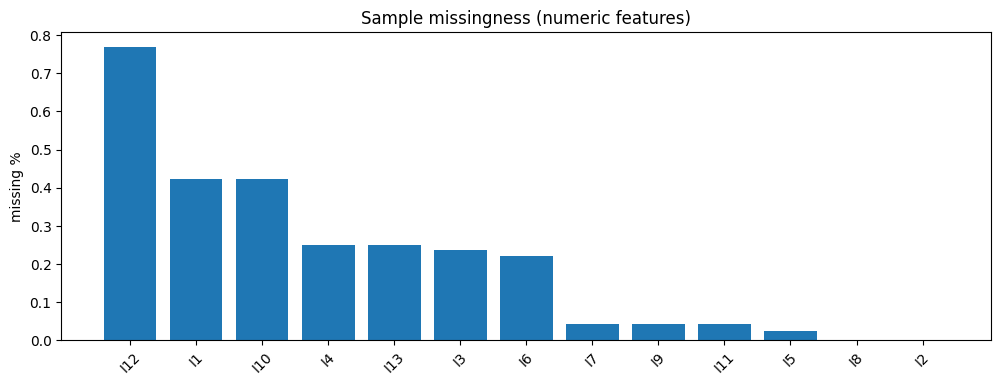

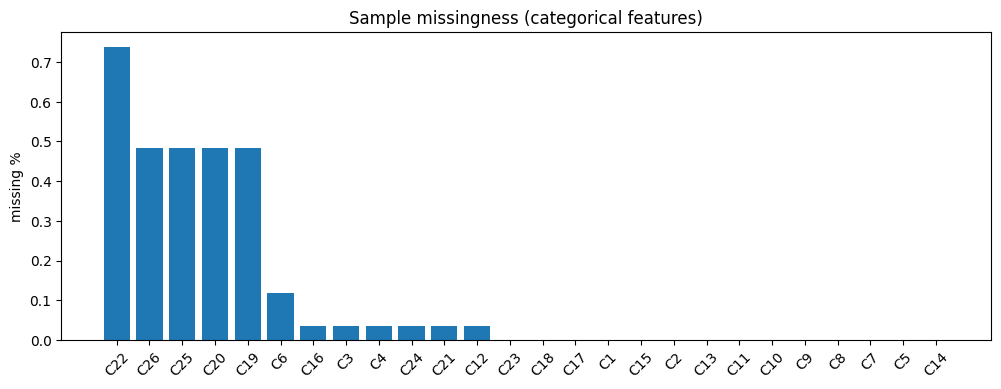

In [32]:
# One compact plot: missingness by feature (numeric vs categorical)
plt.figure(figsize=(12, 4))
plt.bar(missing_numeric.index, missing_numeric['missing_pct'])
plt.title('Sample missingness (numeric features)')
plt.ylabel('missing %')
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(12, 4))
plt.bar(missing_cat.index, missing_cat['missing_pct'])
plt.title('Sample missingness (categorical features)')
plt.ylabel('missing %')
plt.xticks(rotation=45)
plt.show()

## 4. Numerical features (sample stats)
CTR datasets often have numeric features with: 
- very different scales
- heavy tails / outliers
- many zeros

We compute per-feature sample statistics and a *small* number of plots.

In [33]:
def numeric_feature_summary(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    rows = []
    n = len(df)
    for c in cols:
        s = df[c]
        non_missing = s.dropna()
        if len(non_missing) == 0:
            rows.append({
                'feature': c,
                'count': 0,
                'missing_pct': 1.0,
            })
            continue

        q = non_missing.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
        zeros_frac = float((non_missing == 0).mean())
        neg_frac = float((non_missing < 0).mean())

        rows.append({
            'feature': c,
            'count': int(non_missing.shape[0]),
            'missing_pct': float(s.isna().mean()),
            'mean': float(non_missing.mean()),
            'std': float(non_missing.std(ddof=1)),
            'min': float(non_missing.min()),
            'p1': float(q.loc[0.01]),
            'p5': float(q.loc[0.05]),
            'p25': float(q.loc[0.25]),
            'median': float(q.loc[0.5]),
            'p75': float(q.loc[0.75]),
            'p95': float(q.loc[0.95]),
            'p99': float(q.loc[0.99]),
            'max': float(non_missing.max()),
            'n_unique': int(non_missing.nunique(dropna=True)),
            'frac_zeros': zeros_frac,
            'frac_negative': neg_frac,
        })
    return pd.DataFrame(rows).sort_values('feature').reset_index(drop=True)

numeric_summary = numeric_feature_summary(train_sample, numeric_cols)
display(pd.DataFrame({'note': [SAMPLE_NOTE]}))
numeric_summary

,note
0,All statistics below are computed on the first...


,feature,count,missing_pct,mean,std,min,p1,p5,p25,median,p75,p95,p99,max,n_unique,frac_zeros,frac_negative
0,I1,576997,0.423003,3.238400,8.944151,0.0,0.0,0.0,0.0,1.0,3.0,14.0,37.00,780.0,265,0.451576,0.000000
1,I10,576997,0.423003,0.572658,0.679937,0.0,0.0,0.0,0.0,0.0,1.0,2.0,3.00,8.0,9,0.516696,0.000000
2,I11,959166,0.040834,2.507449,4.825370,0.0,0.0,0.0,0.0,1.0,3.0,9.0,23.00,147.0,122,0.253713,0.000000
3,I12,229943,0.770057,0.979991,6.003874,0.0,0.0,0.0,0.0,0.0,0.0,4.0,19.00,768.0,160,0.758410,0.000000
4,I13,750884,0.249116,7.630003,35.071487,0.0,0.0,0.0,2.0,4.0,9.0,26.0,44.00,6702.0,387,0.058607,0.000000
5,I2,1000000,0.000000,93.965184,349.884675,-2.0,-1.0,-1.0,0.0,2.0,32.0,442.0,1986.00,18522.0,4061,0.171148,0.122833
6,I3,764946,0.235054,21.094269,344.010001,0.0,1.0,1.0,2.0,5.0,14.0,59.0,170.00,65535.0,1719,0.004744,0.000000
7,I4,750884,0.249116,6.954270,8.554014,0.0,0.0,1.0,2.0,4.0,9.0,24.0,39.00,507.0,193,0.042415,0.000000
8,I5,975464,0.024536,18616.531735,67686.651149,0.0,0.0,2.0,829.0,2548.0,10163.0,64556.0,336419.11,2527030.0,79185,0.017611,0.000000
9,I6,778260,0.221740,116.761653,456.056847,0.0,0.0,0.0,8.0,33.0,102.0,473.0,1289.00,233523.0,3936,0.064049,0.000000


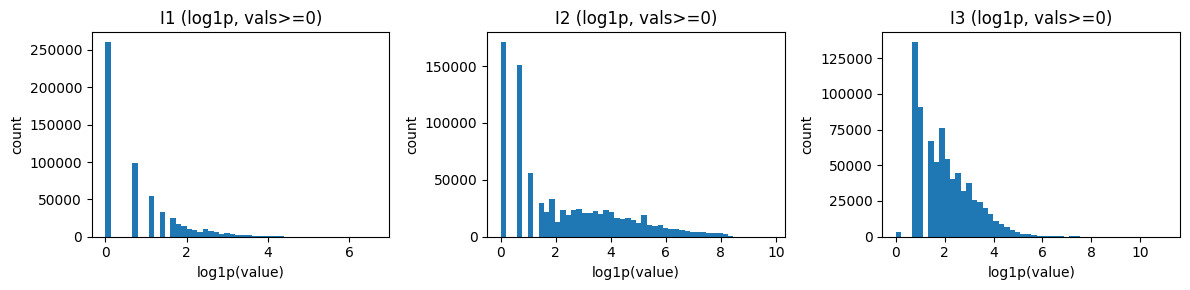

In [34]:
# Minimal plotting: log1p histograms for a few numeric features to reveal skew/heavy tails.
# Note: log1p(x) is only finite for x > -1. Some Criteo integer features can be negative,
# so we filter to non-negative values for these illustrative plots.
example_numeric = [c for c in ['I1', 'I2', 'I3'] if c in numeric_cols]

if len(example_numeric) == 0:
    print('No example numeric features found (unexpected).')
else:
    fig, axes = plt.subplots(1, len(example_numeric), figsize=(4 * len(example_numeric), 3), squeeze=False)
    for ax, c in zip(axes[0], example_numeric):
        vals = train_sample[c].dropna()
        vals = vals[vals >= 0]  # keep log1p finite and interpretable
        if len(vals) == 0:
            ax.text(0.5, 0.5, 'No non-negative values', ha='center', va='center')
            ax.set_axis_off()
            continue
        ax.hist(np.log1p(vals.to_numpy()), bins=50)
        ax.set_title(f'{c} (log1p, vals>=0)')
        ax.set_xlabel('log1p(value)')
        ax.set_ylabel('count')
    plt.tight_layout()
    plt.show()

## 5. Categorical features (sample stats)
CTR prediction often relies heavily on **high-cardinality categorical features** (e.g., user, ad, publisher, context identifiers).

Why it matters:
- we typically represent categoricals via **embeddings**
- high-cardinality + long tails imply many rare categories
- rare categories affect vocabulary/OOV decisions (later)

Below we compute *sample* cardinality and frequency statistics from the first 10K rows.

**Important:** observed cardinality and tail properties from 10K rows will generally **underestimate** full-dataset cardinality and distort long-tail behavior.

In [35]:
def categorical_feature_summary(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    n = len(df)
    rows = []
    thresholds = [2, 5, 10, 100]

    for c in cols:
        s = df[c]
        missing_pct = float(s.isna().mean())

        counts = s.value_counts(dropna=True)
        V = int(counts.shape[0])

        # Rare-category counts (number of categories)
        singletons = int((counts == 1).sum())
        lt5 = int((counts < 5).sum())
        lt10 = int((counts < 10).sum())
        lt100 = int((counts < 100).sum())

        # Frequent-category counts (vocabulary size after thresholding), and traffic coverage (fraction of all rows)
        v_ge = {k: int((counts >= k).sum()) for k in thresholds}
        coverage_ge = {k: float(counts[counts >= k].sum() / n) for k in thresholds}

        top5 = counts.head(5)
        top5_str = ', '.join([f'{idx}:{int(v)}' for idx, v in top5.items()])

        rows.append({
            'feature': c,
            'observed_V': V,
            'missing_pct': missing_pct,
            'singletons': singletons,
            'singletons_pct_of_V': (singletons / V) if V > 0 else np.nan,
            'cats_lt5': lt5,
            'cats_lt10': lt10,
            'cats_lt100': lt100,
            'V_freq>=2': v_ge[2],
            'coverage_freq>=2': coverage_ge[2],
            'V_freq>=5': v_ge[5],
            'coverage_freq>=5': coverage_ge[5],
            'V_freq>=10': v_ge[10],
            'coverage_freq>=10': coverage_ge[10],
            'V_freq>=100': v_ge[100],
            'coverage_freq>=100': coverage_ge[100],
            'top5_categories': top5_str,
        })

    return pd.DataFrame(rows).sort_values('feature').reset_index(drop=True)

cat_summary = categorical_feature_summary(train_sample, cat_cols)
display(pd.DataFrame({'note': [SAMPLE_NOTE]}))
cat_summary.sort_values(by='singletons', ascending=False).head(24)

,note
0,All statistics below are computed on the first...


,feature,observed_V,missing_pct,singletons,singletons_pct_of_V,cats_lt5,cats_lt10,cats_lt100,V_freq>=2,coverage_freq>=2,V_freq>=5,coverage_freq>=5,V_freq>=10,coverage_freq>=10,V_freq>=100,coverage_freq>=100,top5_categories
19,C3,321438,0.036345,277626,0.863700,308533,315067,320721,43812,0.686029,12905,0.609814,6371,0.567838,717,0.424601,"d032c263:30818, b1ecc6c4:9368, 02cf9876:9018, ..."
3,C12,268487,0.036345,224750,0.837098,255405,261994,267745,43737,0.738905,13082,0.663262,6493,0.620990,742,0.475213,"6aaba33c:35934, dfbb09fb:30818, 2436ff75:9368,..."
13,C21,240747,0.036345,197383,0.819877,227620,234195,239974,43364,0.766272,13127,0.691539,6552,0.649211,773,0.501361,"723b4dfd:35934, 0014c32a:30818, 4f1aa25f:9368,..."
7,C16,205923,0.036345,163557,0.794263,192604,199203,205123,42366,0.800098,13319,0.727880,6720,0.685418,800,0.532509,"b041b04a:35934, 84898b2a:30819, f4ead43c:9368,..."
20,C4,120964,0.036345,83428,0.689693,107020,113540,120057,37536,0.880227,13944,0.820295,7424,0.778164,907,0.605697,"c18be181:39839, 29998ed1:35934, d16679b9:20539..."
16,C24,41282,0.036345,21033,0.509496,31952,35778,40432,20249,0.942622,9330,0.914113,5504,0.889104,850,0.757575,"b34f3128:60878, 3fdb382b:56306, 3b183c5c:47840..."
18,C26,30955,0.483901,14687,0.474463,23476,26673,30358,16268,0.501412,7479,0.478327,4282,0.457465,597,0.356557,"49d68486:41432, c27f155b:19602, 2fede552:14541..."
1,C10,30792,0.000000,10957,0.355839,19518,23422,29425,19835,0.989043,11274,0.966061,7370,0.940416,1367,0.763173,"3b08e48b:210107, efea433b:17615, fbbf2c95:9651..."
6,C15,8934,0.000000,1592,0.178196,3531,4763,7632,7342,0.998408,5403,0.993020,4171,0.984831,1302,0.889103,"2d0bb053:25774, d345b1a0:17990, e1ac77f7:11407..."
23,C7,10863,0.000000,741,0.068213,2276,3764,9003,10122,0.999259,8587,0.994856,7099,0.984780,1860,0.796848,"7195046d:15072, dc7659bd:13554, 468a0854:7330,..."


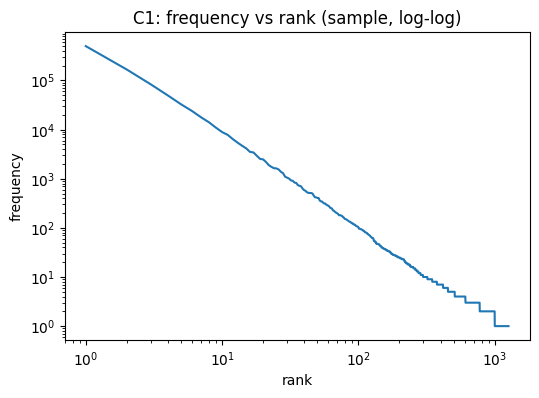

In [36]:
# One illustrative plot: frequency vs. rank (log-log) for a single categorical feature.
# This gives a quick sense of long-tail behavior WITHOUT spamming plots for all features.
example_cat = 'C1'
if example_cat in cat_cols:
    counts = train_sample[example_cat].value_counts(dropna=True)
    freqs = counts.sort_values(ascending=False).values
    ranks = np.arange(1, len(freqs) + 1)

    plt.figure(figsize=(6, 4))
    plt.loglog(ranks, freqs)
    plt.title(f'{example_cat}: frequency vs rank (sample, log-log)')
    plt.xlabel('rank')
    plt.ylabel('frequency')
    plt.show()
else:
    print('C1 not found (unexpected).')

## 6. Illustrative embedding implications (10K-sample only)
Embeddings are a common way to represent categorical features in deep CTR models.

For a categorical feature with:
- `V = observed vocabulary size` (from the 10K sample)
- `d = min(50, ceil(sqrt(V)))`

We compute:
- `embedding_parameters = V * d`
- `embedding_memory_bytes = V * d * 4` (FP32)

**Important:** these are **illustrative 10K-sample estimates** and are *not* full-dataset memory estimates.

In [37]:
def embedding_estimates_from_V(V: int) -> dict:
    if V <= 0:
        return {
            'd': 0,
            'embedding_parameters': 0,
            'embedding_memory_bytes_fp32': 0,
            'embedding_memory_mb_fp32': 0.0,
        }
    d = min(50, int(math.ceil(math.sqrt(V))))
    params = V * d
    mem_bytes = params * 4
    return {
        'd': d,
        'embedding_parameters': int(params),
        'embedding_memory_bytes_fp32': int(mem_bytes),
        'embedding_memory_mb_fp32': float(mem_bytes / (1024 ** 2)),
    }

emb_rows = []
for _, row in cat_summary.iterrows():
    V = int(row['observed_V'])
    est = embedding_estimates_from_V(V)
    emb_rows.append({
        'feature': row['feature'],
        'observed_V': V,
        **est,
    })

emb_summary = pd.DataFrame(emb_rows).sort_values('feature').reset_index(drop=True)
display(pd.DataFrame({'note': ['Illustrative estimates based on 10K-sample observed vocabulary sizes only.']}))
emb_summary.head()

,note
0,Illustrative estimates based on 10K-sample obs...


,feature,observed_V,d,embedding_parameters,embedding_memory_bytes_fp32,embedding_memory_mb_fp32
0,C1,1261,36,45396,181584,0.173172
1,C10,30792,50,1539600,6158400,5.873108
2,C11,4731,50,236550,946200,0.902367
3,C12,268487,50,13424350,53697400,51.209831
4,C13,3068,50,153400,613600,0.585175


## 7. Summary tables (sample)
We consolidate key statistics into a small number of readable tables for quick review.

In [38]:
# Dataset overview
dataset_overview = pd.DataFrame({
    'item': [
        'sample_rows_loaded',
        'target_column',
        'num_numeric_features',
        'num_categorical_features',
        'test_has_label',
        'doc_mentions_chronological_order',
    ],
    'value': [
        SAMPLE_N,
        'label',
        NUM_INT_FEATURES,
        NUM_CAT_FEATURES,
        False,
        ('chronologically ordered' in readme_text.lower()),
    ],
})
display(pd.DataFrame({'note': [SAMPLE_NOTE]}))
dataset_overview

,note
0,All statistics below are computed on the first...


,item,value
0,sample_rows_loaded,1000000
1,target_column,label
2,num_numeric_features,13
3,num_categorical_features,26
4,test_has_label,False
5,doc_mentions_chronological_order,True


In [39]:
# Target distribution table (sample)
target_table = pd.DataFrame({
    'positives': [pos],
    'negatives': [neg],
    'sample_ctr': [sample_ctr],
    'pos_to_neg_ratio': [pos_neg_ratio],
})
target_table

,positives,negatives,sample_ctr,pos_to_neg_ratio
0,254949,745051,0.254949,0.34219


In [40]:
# Numerical feature summary (sample)
numeric_summary

,feature,count,missing_pct,mean,std,min,p1,p5,p25,median,p75,p95,p99,max,n_unique,frac_zeros,frac_negative
0,I1,576997,0.423003,3.238400,8.944151,0.0,0.0,0.0,0.0,1.0,3.0,14.0,37.00,780.0,265,0.451576,0.000000
1,I10,576997,0.423003,0.572658,0.679937,0.0,0.0,0.0,0.0,0.0,1.0,2.0,3.00,8.0,9,0.516696,0.000000
2,I11,959166,0.040834,2.507449,4.825370,0.0,0.0,0.0,0.0,1.0,3.0,9.0,23.00,147.0,122,0.253713,0.000000
3,I12,229943,0.770057,0.979991,6.003874,0.0,0.0,0.0,0.0,0.0,0.0,4.0,19.00,768.0,160,0.758410,0.000000
4,I13,750884,0.249116,7.630003,35.071487,0.0,0.0,0.0,2.0,4.0,9.0,26.0,44.00,6702.0,387,0.058607,0.000000
5,I2,1000000,0.000000,93.965184,349.884675,-2.0,-1.0,-1.0,0.0,2.0,32.0,442.0,1986.00,18522.0,4061,0.171148,0.122833
6,I3,764946,0.235054,21.094269,344.010001,0.0,1.0,1.0,2.0,5.0,14.0,59.0,170.00,65535.0,1719,0.004744,0.000000
7,I4,750884,0.249116,6.954270,8.554014,0.0,0.0,1.0,2.0,4.0,9.0,24.0,39.00,507.0,193,0.042415,0.000000
8,I5,975464,0.024536,18616.531735,67686.651149,0.0,0.0,2.0,829.0,2548.0,10163.0,64556.0,336419.11,2527030.0,79185,0.017611,0.000000
9,I6,778260,0.221740,116.761653,456.056847,0.0,0.0,0.0,8.0,33.0,102.0,473.0,1289.00,233523.0,3936,0.064049,0.000000


In [41]:
# Categorical summary table (sample) with illustrative embedding memory.
cat_summary_with_emb = (
    cat_summary
    .merge(
        emb_summary[['feature', 'd', 'embedding_memory_mb_fp32']],
        on='feature',
        how='left',
    )
)

cat_summary_compact = cat_summary_with_emb[[
    'feature',
    'observed_V',
    'missing_pct',
    'singletons_pct_of_V',
    'V_freq>=5',
    'coverage_freq>=5',
    'V_freq>=10',
    'coverage_freq>=10',
    'd',
    'embedding_memory_mb_fp32',
]]

cat_summary_compact

,feature,observed_V,missing_pct,singletons_pct_of_V,V_freq>=5,coverage_freq>=5,V_freq>=10,coverage_freq>=10,d,embedding_memory_mb_fp32
0,C1,1261,0.000000,0.208565,508,0.998391,320,0.997138,36,0.173172
1,C10,30792,0.000000,0.355839,11274,0.966061,7370,0.940416,50,5.873108
2,C11,4731,0.000000,0.057493,4055,0.998593,3662,0.995923,50,0.902367
3,C12,268487,0.036345,0.837098,13082,0.663262,6493,0.620990,50,51.209831
4,C13,3068,0.000000,0.011082,2934,0.999657,2799,0.998713,50,0.585175
5,C14,26,0.000000,0.000000,26,1.000000,26,1.000000,6,0.000595
6,C15,8934,0.000000,0.178196,5403,0.993020,4171,0.984831,50,1.704025
7,C16,205923,0.036345,0.794263,13319,0.727880,6720,0.685418,50,39.276695
8,C17,10,0.000000,0.000000,10,1.000000,10,1.000000,4,0.000153
9,C18,3881,0.000000,0.133471,2646,0.997486,2161,0.994192,50,0.740242


## Initial observations from the 10K sample
This section intentionally stays **non-prescriptive**. The goal is to capture what we learned and what to validate later at larger scales.

In [42]:
from IPython.display import Markdown, display

# Small helper summaries to keep this short and practical.
top_missing_num = missing_numeric.head(3).reset_index().rename(columns={'index': 'feature'})
top_missing_cat = missing_cat.head(3).reset_index().rename(columns={'index': 'feature'})

max_observed_V = int(cat_summary['observed_V'].max())
max_observed_V_feature = cat_summary.sort_values('observed_V', ascending=False).iloc[0]['feature']

md = '\n'.join([
    '### 1) Important properties observed',
    f'- Sample CTR (first {SAMPLE_N:,} rows): **{sample_ctr:.4%}** (positives={pos:,}, negatives={neg:,}).',
    '- Missingness is present in both numeric and categorical features (see missingness tables/plots).',
    '- Some numeric features show skew/heavy tails (see log1p hist examples).',
    f'- Categorical features show many rare categories even in a 10K sample; the highest observed sample cardinality is **{max_observed_V:,}** for **{max_observed_V_feature}**.',
    '',
    '### 2) Anything surprising',
    '- (Fill in after review) e.g., unusually high missingness in a specific feature, extreme outliers, many zeros, etc.',
    '',
    '### 3) Likely unreliable due to only 10K rows',
    '- Observed categorical cardinalities (`observed_V`) will **underestimate** the full dataset vocabulary sizes.',
    '- Rare-category rates (singletons / freq<k) and tail shape may change substantially with more data.',
    '- Any feature correlations or stability over time cannot be assessed from this small slice.',
    '',
    '### 4) Questions to investigate at larger sample sizes (e.g., 100K, 1M, …)',
    '- How do observed vocabulary sizes and rare-category rates scale with more rows?',
    '- Are missingness patterns stable across time (remember: docs say rows are chronologically ordered)?',
    '- Which numeric features have the heaviest tails / largest scale differences as we scale up?',
    '- How do embedding-memory implications change once we compute vocabularies on larger samples?',
])

display(Markdown(md))

display(Markdown('**Top missing numeric features (sample):**'))
display(top_missing_num)

display(Markdown('**Top missing categorical features (sample):**'))
display(top_missing_cat)

### 1) Important properties observed
- Sample CTR (first 1,000,000 rows): **25.4949%** (positives=254,949, negatives=745,051).
- Missingness is present in both numeric and categorical features (see missingness tables/plots).
- Some numeric features show skew/heavy tails (see log1p hist examples).
- Categorical features show many rare categories even in a 10K sample; the highest observed sample cardinality is **321,438** for **C3**.

### 2) Anything surprising
- (Fill in after review) e.g., unusually high missingness in a specific feature, extreme outliers, many zeros, etc.

### 3) Likely unreliable due to only 10K rows
- Observed categorical cardinalities (`observed_V`) will **underestimate** the full dataset vocabulary sizes.
- Rare-category rates (singletons / freq<k) and tail shape may change substantially with more data.
- Any feature correlations or stability over time cannot be assessed from this small slice.

### 4) Questions to investigate at larger sample sizes (e.g., 100K, 1M, …)
- How do observed vocabulary sizes and rare-category rates scale with more rows?
- Are missingness patterns stable across time (remember: docs say rows are chronologically ordered)?
- Which numeric features have the heaviest tails / largest scale differences as we scale up?
- How do embedding-memory implications change once we compute vocabularies on larger samples?

**Top missing numeric features (sample):**

,feature,missing_count,missing_pct
0,I12,770057,0.770057
1,I1,423003,0.423003
2,I10,423003,0.423003


**Top missing categorical features (sample):**

,feature,missing_count,missing_pct
0,C22,738959,0.738959
1,C26,483901,0.483901
2,C25,483901,0.483901
